# 🤟 Indian Sign Language (ISL) Video Preprocessing Pipeline
### Emergency Sign Recognition Dataset (`accident`, `call`, `doctor`, `help`, `hot`, `lose`, `pain`, `thief`)

This notebook implements an end-to-end data preprocessing pipeline for **Indian Sign Language (ISL) Emergency Gestures**.

### 🎯 Objectives:
1. **Video Ingestion**: Read raw gesture videos across 8 emergency categories from `ISL_Emergency_Sign_dataset`.
2. **Landmark Extraction**: Extract 3D hand keypoints using **MediaPipe Hands** (21 landmarks $\times$ 3 coordinates $[x, y, z]$ per hand $\rightarrow$ **126 features per frame**).
3. **Relative Anchoring & Normalization**: Normalize landmark coordinates relative to the wrist to ensure translational and position invariance.
4. **Sequence Length Standardization**: Standardize variable duration videos to a fixed length of **30 frames** via uniform temporal sampling or zero-padding.
5. **Serialization**: Save the processed `(30, 126)` sequences as `.npy` files under `data/<word>/`, ready for BiLSTM / GRU / Transformer training and real-time sign recognition.

## 1. Install & Import Dependencies
Verify required packages: `opencv-python`, `mediapipe`, `numpy`, and `matplotlib`.

In [8]:
# Optional dependency installation if not already installed
# !pip install opencv-python mediapipe numpy matplotlib tqdm

import os
import sys
import time
import urllib.request
from collections import Counter
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp

print("OpenCV Version   :", cv2.__version__)
print("NumPy Version    :", np.__version__)
print("MediaPipe Version:", mp.__version__)
print("Python Version   :", sys.version.split()[0])

OpenCV Version   : 5.0.0
NumPy Version    : 2.5.4
MediaPipe Version: 1.2.0
Python Version   : 3.14.7


## 2. Configuration & Directory Setup
Define the 8 target gesture classes, sequence parameters, and input/output directory paths.

In [9]:
# Target emergency vocabulary (8 classes)
WORDS = ["accident", "call", "doctor", "help", "hot", "lose", "pain", "thief"]

# Sequence parameters
SEQUENCE_LENGTH = 30  # Standard fixed number of frames per video sequence
NUM_HANDS = 2        # Left and Right hands
LANDMARKS_PER_HAND = 21
COORDS_PER_LANDMARK = 3  # (x, y, z)
FEATURE_DIM = NUM_HANDS * LANDMARKS_PER_HAND * COORDS_PER_LANDMARK  # 126

# Directory paths
PROJECT_ROOT = Path.cwd()
INPUT_VIDEOS_DIR = PROJECT_ROOT / "ISL_Emergency_Sign_dataset"
if not INPUT_VIDEOS_DIR.exists():
    INPUT_VIDEOS_DIR = PROJECT_ROOT / "ISL_Emergency_sign_dataset"

OUTPUT_DATA_DIR = PROJECT_ROOT / "data"

# Create class folders inside data/
OUTPUT_DATA_DIR.mkdir(parents=True, exist_ok=True)
for word in WORDS:
    (OUTPUT_DATA_DIR / word).mkdir(parents=True, exist_ok=True)

print(f"Target Words ({len(WORDS)}): {WORDS}")
print(f"Sequence Length : {SEQUENCE_LENGTH} frames")
print(f"Feature Dim     : {FEATURE_DIM} (2 hands x 21 landmarks x 3 coords)")
print(f"Input Directory : {INPUT_VIDEOS_DIR}")
print(f"Output Directory: {OUTPUT_DATA_DIR}")

Target Words (8): ['accident', 'call', 'doctor', 'help', 'hot', 'lose', 'pain', 'thief']
Sequence Length : 30 frames
Feature Dim     : 126 (2 hands x 21 landmarks x 3 coords)
Input Directory : d:\model training\ISL recognition\ISL_Emergency_Sign_dataset
Output Directory: d:\model training\ISL recognition\data


## 3. Initialize MediaPipe Hands Model
MediaPipe provides real-time 3D hand keypoints. The cell below automatically configures the **modern Tasks API** (`vision.HandLandmarker`) with automatic download of `hand_landmarker.task` if needed, while retaining fallback support for the legacy `mp.solutions.hands` API.

In [10]:
# Check for legacy vs modern MediaPipe API
USE_LEGACY_SOLUTIONS = hasattr(mp, 'solutions')

if USE_LEGACY_SOLUTIONS:
    mp_hands = mp.solutions.hands
    hands_model = mp_hands.Hands(
        static_image_mode=False,
        max_num_hands=2,
        min_detection_confidence=0.5,
        min_tracking_confidence=0.5
    )
    print("MediaPipe Hands initialized using legacy solutions API.")
else:
    from mediapipe.tasks import python
    from mediapipe.tasks.python import vision

    MODEL_PATH = PROJECT_ROOT / "hand_landmarker.task"
    if not MODEL_PATH.exists():
        model_url = "https://storage.googleapis.com/mediapipe-models/hand_landmarker/hand_landmarker/float16/latest/hand_landmarker.task"
        print(f"Downloading hand_landmarker.task from {model_url}...")
        urllib.request.urlretrieve(model_url, str(MODEL_PATH))
        print("Download complete.")

    base_options = python.BaseOptions(model_asset_path=str(MODEL_PATH))
    options = vision.HandLandmarkerOptions(
        base_options=base_options,
        running_mode=vision.RunningMode.IMAGE,
        num_hands=2,
        min_hand_detection_confidence=0.5,
        min_hand_presence_confidence=0.5,
        min_tracking_confidence=0.5
    )
    hands_model = vision.HandLandmarker.create_from_options(options)
    print("MediaPipe HandLandmarker initialized using modern Tasks API.")

MediaPipe HandLandmarker initialized using modern Tasks API.


## 4. Landmark Extraction & Normalization Functions

### Feature Layout:
- **Left Hand Keypoints (0 to 62)**: 21 landmarks $\times$ $(x, y, z)$. If Left Hand is absent, filled with zeros.
- **Right Hand Keypoints (63 to 125)**: 21 landmarks $\times$ $(x, y, z)$. If Right Hand is absent, filled with zeros.

### Spatial & Temporal Normalization:
1. **Wrist Anchoring (`normalize_sequence`)**: Positions coordinates relative to the detected wrist (Right wrist anchor `[63:66]` or Left wrist anchor `[0:3]`) to ensure translational position invariance.
2. **Temporal Resampling (`standardize_length`)**: Videos with $>30$ frames are uniformly downsampled using `np.linspace(0, N-1, 30)`, while shorter videos ($<30$ frames) are zero-padded to 30 frames.

In [11]:
def extract_hand_landmarks(frame):
    """
    Extracts 21 3D coordinates for Left and Right hands from a BGR image frame.
    Returns a 126-dimensional float32 vector: [left_hand (63), right_hand (63)].
    """
    image_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    left_hand = np.zeros(63, dtype=np.float32)
    right_hand = np.zeros(63, dtype=np.float32)

    if USE_LEGACY_SOLUTIONS:
        results = hands_model.process(image_rgb)
        if results.multi_hand_landmarks and results.multi_handedness:
            for hand_landmarks, handedness in zip(results.multi_hand_landmarks, results.multi_handedness):
                coords = np.array([[lm.x, lm.y, lm.z] for lm in hand_landmarks.landmark], dtype=np.float32).flatten()
                label = handedness.classification[0].label
                if label == "Left":
                    left_hand = coords
                else:
                    right_hand = coords
    else:
        mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=image_rgb)
        results = hands_model.detect(mp_image)
        if results.hand_landmarks and results.handedness:
            for hand_landmarks, handedness in zip(results.hand_landmarks, results.handedness):
                coords = np.array([[lm.x, lm.y, lm.z] for lm in hand_landmarks], dtype=np.float32).flatten()
                label = handedness[0].category_name
                if label == "Left":
                    left_hand = coords
                else:
                    right_hand = coords

    return np.concatenate([left_hand, right_hand])


def normalize_sequence(sequence):
    """
    Normalizes coordinates relative to the wrist anchor.
    Anchor is chosen from Right wrist (indices 63:66) or Left wrist (indices 0:3).
    """
    normalized = sequence.copy()
    for i in range(len(normalized)):
        frame_landmarks = normalized[i]
        if np.any(frame_landmarks[63:66]):
            anchor = frame_landmarks[63:66].copy()
        elif np.any(frame_landmarks[0:3]):
            anchor = frame_landmarks[0:3].copy()
        else:
            continue
        for j in range(0, 126, 3):
            frame_landmarks[j:j+3] -= anchor
    return normalized


def standardize_length(sequence, target_length=SEQUENCE_LENGTH):
    """
    Resamples or pads the sequence to exactly `target_length` frames.
    """
    current_length = len(sequence)
    if current_length == target_length:
        return sequence
    elif current_length > target_length:
        indices = np.linspace(0, current_length - 1, target_length).astype(int)
        return sequence[indices]
    else:
        pad_width = target_length - current_length
        padding = np.zeros((pad_width, sequence.shape[1]), dtype=np.float32)
        return np.vstack([sequence, padding])


def process_video(video_path):
    """
    End-to-end processing of a single video file:
    1. Extracts frame landmarks
    2. Anchors & normalizes keypoints
    3. Resamples to target sequence length (30 frames)
    Returns numpy array of shape (30, 126) or None on failure.
    """
    cap = cv2.VideoCapture(str(video_path))
    frame_landmarks_list = []

    while cap.isOpened():
        ret, frame = cap.read()
        if not ret:
            break
        landmarks = extract_hand_landmarks(frame)
        frame_landmarks_list.append(landmarks)
    cap.release()

    if len(frame_landmarks_list) == 0:
        return None

    sequence = np.array(frame_landmarks_list, dtype=np.float32)
    sequence = normalize_sequence(sequence)
    sequence = standardize_length(sequence, target_length=SEQUENCE_LENGTH)
    return sequence

## 5. Single Video Verification & Landmark Visualization
Run a test on one video sample and inspect the extracted trajectories across 30 frames.

Testing pipeline on: accident_Crop  (1).mp4
Extraction time: 1.52 seconds
Output array shape: (30, 126) (Expected: (30, 126))
Value range: min=-0.984, max=0.950, mean=-0.158


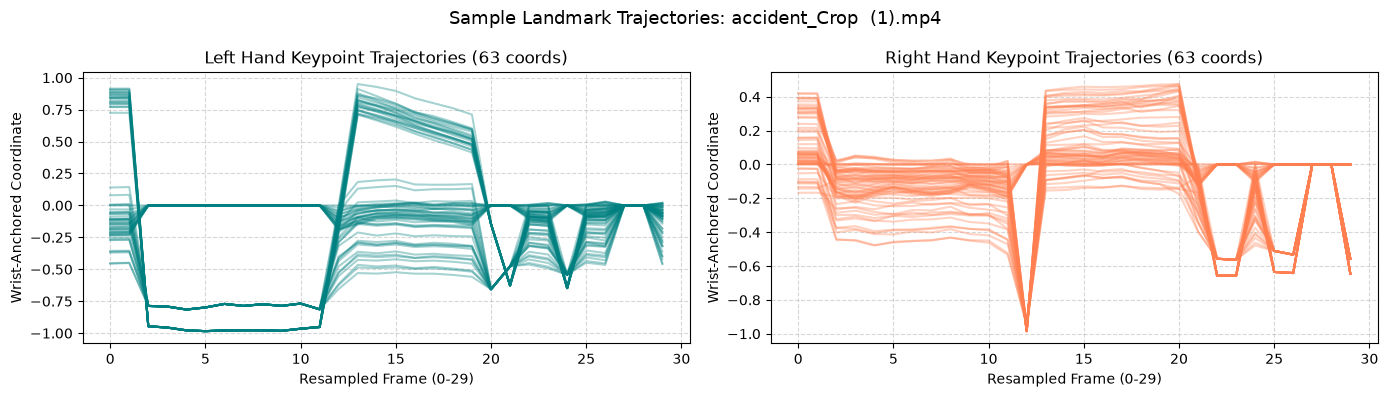

In [12]:
# Find a sample video from 'accident'
sample_dir = INPUT_VIDEOS_DIR / "accident_Cropped"
if not sample_dir.exists():
    sample_dir = INPUT_VIDEOS_DIR / "accident"

sample_candidates = list(sample_dir.glob("*.mp4")) + list(sample_dir.glob("*.avi"))
if sample_candidates:
    sample_video = sample_candidates[0]
    print(f"Testing pipeline on: {sample_video.name}")
    t0 = time.time()
    test_seq = process_video(sample_video)
    t1 = time.time()

    print(f"Extraction time: {t1 - t0:.2f} seconds")
    print(f"Output array shape: {test_seq.shape} (Expected: (30, 126))")
    print(f"Value range: min={test_seq.min():.3f}, max={test_seq.max():.3f}, mean={test_seq.mean():.3f}")

    # Visualize hand coordinate evolution across the 30 frames
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].plot(test_seq[:, :63], alpha=0.35, color="teal")
    axes[0].set_title("Left Hand Keypoint Trajectories (63 coords)")
    axes[0].set_xlabel("Resampled Frame (0-29)")
    axes[0].set_ylabel("Wrist-Anchored Coordinate")
    axes[0].grid(True, linestyle="--", alpha=0.5)

    axes[1].plot(test_seq[:, 63:], alpha=0.35, color="coral")
    axes[1].set_title("Right Hand Keypoint Trajectories (63 coords)")
    axes[1].set_xlabel("Resampled Frame (0-29)")
    axes[1].set_ylabel("Wrist-Anchored Coordinate")
    axes[1].grid(True, linestyle="--", alpha=0.5)

    plt.suptitle(f"Sample Landmark Trajectories: {sample_video.name}", fontsize=13)
    plt.tight_layout()
    plt.show()
else:
    print("No sample video found in", sample_dir)

## 6. Batch Video Preprocessing Pipeline
Processes all video recordings across all 8 classes:
- Identifies both `.avi` and `.mp4` video files in each class folder.
- Handles naming deterministically (preserving both format variants when stems match).
- Skips videos already preprocessed to allow safe resumption.
- Saves outputs into `data/<word>/<video_stem>.npy`.

In [13]:
def process_all_videos():
    """
    Processes all videos across the 8 sign classes and saves .npy arrays in the data/ directory.
    """
    total_processed = 0
    total_skipped = 0
    total_failed = 0
    start_time = time.time()

    for word in WORDS:
        # Folder path check with or without '_Cropped'
        word_input_dir = INPUT_VIDEOS_DIR / f"{word}_Cropped"
        if not word_input_dir.exists():
            word_input_dir = INPUT_VIDEOS_DIR / word

        word_output_dir = OUTPUT_DATA_DIR / word
        word_output_dir.mkdir(parents=True, exist_ok=True)

        if not word_input_dir.exists():
            print(f"[SKIP] No directory found for word '{word}' at {word_input_dir}")
            continue

        video_files = [f for f in os.listdir(word_input_dir) if f.lower().endswith(('.mp4', '.avi', '.mov', '.mkv'))]
        stems = [os.path.splitext(f)[0] for f in video_files]
        stem_counts = Counter(stems)

        print(f"\nProcessing '{word}': {len(video_files)} videos found...")

        for idx, video_file in enumerate(video_files):
            stem = os.path.splitext(video_file)[0]
            ext = os.path.splitext(video_file)[1].lstrip(".").lower()
            save_name = f"{stem}_{ext}.npy" if stem_counts[stem] > 1 else f"{stem}.npy"
            save_path = word_output_dir / save_name

            # If file already exists and valid, skip processing
            if save_path.exists():
                total_skipped += 1
                if (idx + 1) % 20 == 0 or (idx + 1) == len(video_files):
                    print(f"  ...processed {idx+1}/{len(video_files)} for '{word}' (cached)")
                continue

            video_path = word_input_dir / video_file
            sequence = process_video(video_path)

            if sequence is not None:
                np.save(str(save_path), sequence.astype(np.float32))
                total_processed += 1
            else:
                total_failed += 1
                print(f"  [FAILED] {video_file}")

            if (idx + 1) % 20 == 0 or (idx + 1) == len(video_files):
                print(f"  ...processed {idx+1}/{len(video_files)} for '{word}'")

    elapsed = time.time() - start_time
    print("\n" + "=" * 60)
    print(f"PREPROCESSING SUMMARY:")
    print(f"Newly Processed: {total_processed}")
    print(f"Already Cached : {total_skipped}")
    print(f"Failed Videos  : {total_failed}")
    print(f"Total Time     : {elapsed:.2f} seconds ({elapsed/60:.2f} minutes)")
    print(f"All landmark .npy files saved under: {OUTPUT_DATA_DIR.resolve()}")
    print("=" * 60)

process_all_videos()


Processing 'accident': 102 videos found...
  ...processed 20/102 for 'accident' (cached)
  ...processed 40/102 for 'accident' (cached)
  ...processed 60/102 for 'accident' (cached)
  ...processed 80/102 for 'accident' (cached)
  ...processed 100/102 for 'accident' (cached)
  ...processed 102/102 for 'accident' (cached)

Processing 'call': 102 videos found...
  ...processed 20/102 for 'call' (cached)
  ...processed 40/102 for 'call' (cached)
  ...processed 60/102 for 'call' (cached)
  ...processed 80/102 for 'call' (cached)
  ...processed 100/102 for 'call' (cached)
  ...processed 102/102 for 'call' (cached)

Processing 'doctor': 102 videos found...
  ...processed 20/102 for 'doctor' (cached)
  ...processed 40/102 for 'doctor' (cached)
  ...processed 60/102 for 'doctor' (cached)
  ...processed 80/102 for 'doctor' (cached)
  ...processed 100/102 for 'doctor' (cached)
  ...processed 102/102 for 'doctor' (cached)

Processing 'help': 102 videos found...
  ...processed 20/102 for 'help' (ca

## 7. Dataset Validation & Quality Analysis
Verify the integrity of all generated `.npy` files:
- Verify all files match the exact shape `(30, 126)`.
- Ensure all values are finite (no NaNs or Infs).
- Display class sample counts and plot class distribution.

Dataset Validation & Class Distribution Check
  Class 'accident  ': 102 valid .npy sequences
  Class 'call      ': 102 valid .npy sequences
  Class 'doctor    ': 102 valid .npy sequences
  Class 'help      ': 102 valid .npy sequences
  Class 'hot       ': 100 valid .npy sequences
  Class 'lose      ': 100 valid .npy sequences
  Class 'pain      ': 100 valid .npy sequences
  Class 'thief     ': 100 valid .npy sequences
Total Valid Sequences : 808
Total Corrupt/Invalid : 0


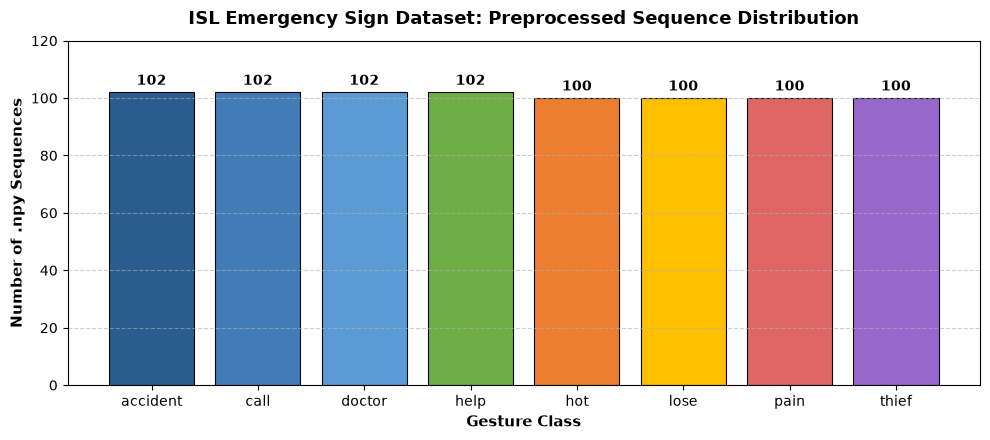

In [14]:
def validate_preprocessed_dataset():
    """
    Verifies all generated .npy files for shape consistency and valid values.
    """
    class_counts = {}
    valid_count = 0
    corrupt_count = 0

    print("=" * 60)
    print("Dataset Validation & Class Distribution Check")
    print("=" * 60)

    for word in WORDS:
        class_dir = OUTPUT_DATA_DIR / word
        npy_files = list(class_dir.glob("*.npy"))
        class_counts[word] = len(npy_files)

        for f in npy_files:
            try:
                arr = np.load(f, allow_pickle=False)
                if arr.shape != (SEQUENCE_LENGTH, FEATURE_DIM) or not np.isfinite(arr).all():
                    corrupt_count += 1
                    print(f"  [CORRUPT] {f.name}: shape={arr.shape}, finite={np.isfinite(arr).all()}")
                else:
                    valid_count += 1
            except Exception as e:
                corrupt_count += 1
                print(f"  [ERROR] {f.name}: {e}")

        print(f"  Class '{word:10s}': {len(npy_files):3d} valid .npy sequences")

    print("=" * 60)
    print(f"Total Valid Sequences : {valid_count}")
    print(f"Total Corrupt/Invalid : {corrupt_count}")
    print("=" * 60)

    # Plot Class Distribution Bar Chart
    plt.figure(figsize=(10, 4.5))
    palette = ["#2b5c8f", "#417bb8", "#5b9bd5", "#70ad47", "#ed7d31", "#ffc000", "#e06666", "#9966cc"]
    bars = plt.bar(class_counts.keys(), class_counts.values(), color=palette[:len(class_counts)], edgecolor="black", linewidth=0.8)

    plt.title("ISL Emergency Sign Dataset: Preprocessed Sequence Distribution", fontsize=13, fontweight="bold", pad=12)
    plt.xlabel("Gesture Class", fontsize=11, fontweight="bold")
    plt.ylabel("Number of .npy Sequences", fontsize=11, fontweight="bold")
    plt.ylim(0, max(class_counts.values(), default=100) + 18)
    plt.grid(axis="y", linestyle="--", alpha=0.6)

    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width() / 2, height + 1.5, f"{height}", ha="center", va="bottom", fontsize=10, fontweight="bold")

    plt.tight_layout()
    plt.show()

validate_preprocessed_dataset()

## 8. Summary & Next Steps for Model Training and Inference

### ✅ Preprocessing Accomplished:
- **Dataset**: 8 emergency gesture classes (`accident`, `call`, `doctor`, `help`, `hot`, `lose`, `pain`, `thief`).
- **Feature Shape**: Each sample is a NumPy array of shape `(30, 126)` representing 30 standardized temporal frames and 126 wrist-anchored 3D hand keypoints.
- **Storage**: Stored under `data/<class_name>/<sample_name>.npy`.

### 🚀 Next Steps:
1. **Model Training (`ISLModel_Training.ipynb`)**:
   - Load the `(30, 126)` sequences from `data/`.
   - Train an 8-class deep sequence model (e.g., Bidirectional LSTM with BatchNorm, Dropout, and AdamW optimizer in PyTorch).
   - Save the best model checkpoint (e.g. `isl_lstm_best_model.pth`) and label map (`label_map.json`).
2. **Real-Time Sign Prediction (`realtime_inference.py`)**:
   - Stream live webcam frames with OpenCV.
   - Extract hand landmarks on the fly using MediaPipe.
   - Maintain a sliding window buffer of 30 frames.
   - Predict the performed gesture in real-time with confidence scores.